In [1]:
   %load_ext autoreload
   %autoreload 2

In [2]:
import sys; print(sys.executable)

/Users/dr_bolty/ai_diag/.venv/bin/python


In [3]:
import pydicom

In [4]:
from pydicom.data import get_testdata_file

In [6]:
get_testdata_file("CT_small.dcm")

'/Users/dr_bolty/ai_diag/.venv/lib/python3.11/site-packages/pydicom/data/test_files/CT_small.dcm'

In [9]:
ds = pydicom.dcmread('/Users/dr_bolty/ai_diag/.venv/lib/python3.11/site-packages/pydicom/data/test_files/CT_small.dcm')

In [10]:
print(ds)

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 192
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: CT Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.3.6.1.4.1.5962.1.1.1.1.1.20040119072730.12322
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.3.6.1.4.1.5962.2
(0002,0013) Implementation Version Name         SH: 'DCTOOL100'
(0002,0016) Source Application Entity Title     AE: 'CLUNIE1'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', 'AXIAL']
(0008,0012) Instance Creation Date              DA: '20040119'
(0008,0013) Instance Creation Time              TM: '072731'
(0008,0014) Instance Creator UID                UI: 1.3.6.1.4.

In [11]:
print(ds.file_meta)

(0002,0000) File Meta Information Group Length  UL: 192
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: CT Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.3.6.1.4.1.5962.1.1.1.1.1.20040119072730.12322
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.3.6.1.4.1.5962.2
(0002,0013) Implementation Version Name         SH: 'DCTOOL100'
(0002,0016) Source Application Entity Title     AE: 'CLUNIE1'


In [12]:
print(ds.file_meta.TransferSyntaxUID.name)

Explicit VR Little Endian


In [15]:
print(ds.Modality)

CT


In [20]:
print(ds[0x0008, 0x0060])

(0008,0060) Modality                            CS: 'CT'


In [21]:
print(ds[0x0008, 0x0060].value)

CT


In [24]:
print(ds.get("ViewPosition"))

None


In [25]:
gg = ["PatientName", "Modality", "StudyInstanceUID", "SeriesInstanceUID", "SOPInstanceUID", "Rows", "Columns", "PixelSpacing", "BitsStored", "RescaleSlope", "RescaleIntercept"]

for g in gg:
    print(ds.get(g))

CompressedSamples^CT1
CT
1.3.6.1.4.1.5962.1.2.1.20040119072730.12322
1.3.6.1.4.1.5962.1.3.1.1.20040119072730.12322
1.3.6.1.4.1.5962.1.1.1.1.1.20040119072730.12322
128
128
[0.661468, 0.661468]
16
1
-1024


In [26]:
arr = ds.pixel_array

In [50]:
import numpy as np

arr = np.float32(arr)

x = arr * 1 + (-1024)


print("Min: ", np.min(x))
print("Max: ", np.max(x))

Min:  -896.0
Max:  1167.0


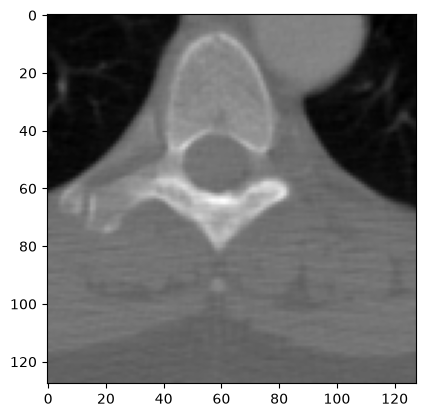

In [51]:
import matplotlib.pyplot as plt

plt.imshow(arr, cmap="gray")

In [84]:
def apply_window(img, center, width):

    if width == 0:
        return np.zeros_like(img, dtype=np.uint8)
        
    low = center - width/2
    high = center + width/2
    
    new_img = np.clip(img, low, high)

    scaled_img = ((new_img - low) / width) *255

    return scaled_img.astype(np.uint8)
    

In [86]:
apply_window(arr, 40, 400)

array([[213, 216, 207, ..., 231, 233, 239],
       [220, 218, 202, ..., 217, 223, 254],
       [219, 216, 211, ..., 198, 206, 251],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], shape=(128, 128), dtype=uint8)

In [85]:
apply_window(arr, -600, 1500)

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], shape=(128, 128), dtype=uint8)

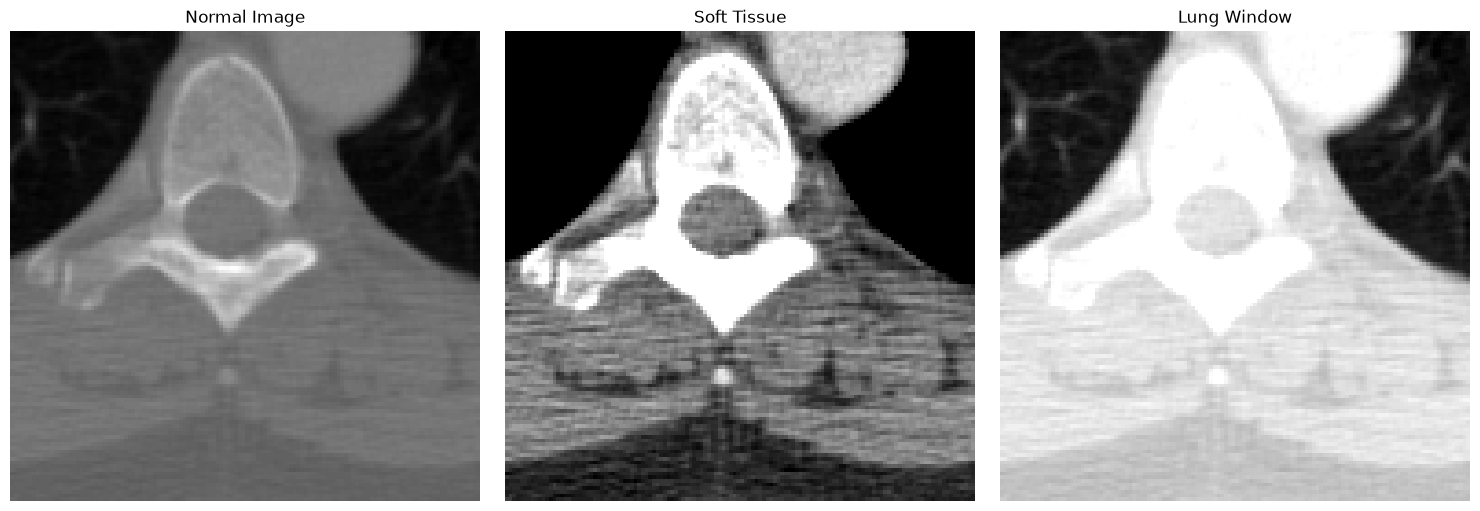

In [87]:
soft_tissue = apply_window(x, center = 40, width = 400)
lung_window = apply_window(x, center = -600, width = 1500)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15,5))

ax1.set_title("Normal Image")
ax1.imshow(arr, cmap = "gray")
ax1.axis("off")

ax2.set_title("Soft Tissue")
ax2.imshow(soft_tissue, cmap = "gray")
ax2.axis("off")

ax3.set_title("Lung Window")
ax3.imshow(lung_window, cmap = "gray")
ax3.axis("off")

plt.tight_layout()
plt.show()


In [88]:
print(soft_tissue.min(), soft_tissue.max())   # should be 0 and 255

0 255


In [89]:
test = np.array([-1000, -160, 40, 240, 1000], dtype=np.float32)
print(apply_window(test, center=40, width=400))

[  0   0 127 255 255]


In [9]:
import json

from pydicom.data import get_testdata_file
from src.data.dicom_io import load_dicom, to_display

img, meta = load_dicom(get_testdata_file("CT_small.dcm"))

print(img.dtype, img.min(), img.max())
print(json.dumps(meta, indent=2))             

gg = to_display(img)
dd = to_display(img, 40, 400)
print(gg)
print(gg.min(), gg.max())
print(dd)

float32 -896.0 1167.0
{
  "patient_id": "1CT1",
  "patient_sex": "O",
  "patient_age": "000Y",
  "modality": "CT",
  "view_position": null,
  "rows": 128,
  "columns": 128,
  "pixel_spacing": [
    0.661468,
    0.661468
  ],
  "study_uid": "1.3.6.1.4.1.5962.1.2.1.20040119072730.12322",
  "series_uid": "1.3.6.1.4.1.5962.1.3.1.1.20040119072730.12322",
  "sop_uid": "1.3.6.1.4.1.5962.1.1.1.1.1.20040119072730.12322"
}
[[  5   6   4 ...   9   9  10]
 [  7   6   3 ...   6   7  13]
 [  6   6   5 ...   2   4  13]
 ...
 [ 96  96  98 ...  98  99  98]
 [ 97 102 100 ... 100  98  96]
 [102 102  97 ...  96  95  96]]
0 255
[[ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 [ 0  0  0 ...  0  0  0]
 ...
 [26 29 37 ... 36 41 40]
 [31 57 47 ... 49 38 26]
 [60 58 33 ... 29 25 28]]
